# 01. Exploración y análisis de datos

## Clasificador de conversaciones de telecomunicaciones

### Objetivo

Realizar un análisis exploratorio del conjunto de datos `CustomerInteractionData.csv` para comprender su estructura, identificar problemas de calidad, estudiar la distribución de las categorías y analizar las características de los mensajes.

Esta etapa permitirá identificar posibles dificultades en los datos y establecer criterios para el posterior desarrollo de modelos de clasificación de texto.

### Fuente de datos

- **Archivo:** `CustomerInteractionData.csv`
- **Variable de entrada:** `CustomerInteractionRawText`
- **Variable objetivo:** `AgentAssignedTopic`

### Alcance

1. Inspección de la estructura del conjunto de datos.
2. Análisis de calidad y consistencia.
3. Distribución de las categorías.
4. Análisis de longitud y contenido de los mensajes.
5. Identificación de patrones y posibles dificultades de clasificación.
6. Conclusiones para la etapa de modelado.

## 2. Carga de datos y librerías

En esta sección se importan las librerías necesarias para la exploración y se carga el conjunto de datos que se utilizará durante el análisis.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Ruta del proyecto
BASE_DIR = Path.cwd().parent
DATA_PATH = BASE_DIR / "data" / "CustomerInteractionData.csv"

# Carga del conjunto de datos
df = pd.read_csv(DATA_PATH)

print("Dataset cargado correctamente.")

Dataset cargado correctamente.


## 3. Exploración inicial del conjunto de datos

Se examinan las dimensiones, los nombres de las columnas, los tipos de datos y una muestra de registros para comprender la estructura del dataset.

In [3]:
print("Dimensiones del dataset:", df.shape)

print("\nColumnas:")
print(df.columns.tolist())

print("\nTipos de datos:")
display(df.dtypes)

print("\nPrimeros cinco registros:")
display(df.head())

Dimensiones del dataset: (103, 7)

Columnas:
['RecordID', 'CustomerInteractionRawText', 'AgentAssignedTopic', 'LocationID', 'CallDurationSeconds', 'AgentID', 'CustomerID']

Tipos de datos:


RecordID                        int64
CustomerInteractionRawText        str
AgentAssignedTopic                str
LocationID                    float64
CallDurationSeconds           float64
AgentID                           str
CustomerID                        str
dtype: object


Primeros cinco registros:


,RecordID,CustomerInteractionRawText,AgentAssignedTopic,LocationID,CallDurationSeconds,AgentID,CustomerID
0,1890041,Cus not satisfied with service. want to port o...,Port Out,8.0,10.0,z88Nr,5Ms7y
1,1890042,Jadav called to check his porting out status. ...,Port Out,1.0,6.0,xGAVI,s8Zyb
2,1890043,Customer thraetened to cancel her service. Sai...,Port Out,9.0,15.0,T7Kdd,3IB8J
3,1890044,called to ask steps for porting out. She is le...,Port Out,5.0,15.0,jtifd,mtR3W
4,1890045,Customer dissatisfied with support. Connectivi...,Port Out,7.0,13.0,hxY3d,DbBmN


In [4]:
# Valores faltantes por columna
print("Valores faltantes por columna:")
display(df.isnull().sum())

# Porcentaje de valores faltantes
print("\nPorcentaje de valores faltantes:")
display((df.isnull().mean() * 100).round(2))

# Registros duplicados
print("\nRegistros duplicados:", df.duplicated().sum())

Valores faltantes por columna:


RecordID                      0
CustomerInteractionRawText    0
AgentAssignedTopic            0
LocationID                    3
CallDurationSeconds           1
AgentID                       1
CustomerID                    1
dtype: int64


Porcentaje de valores faltantes:


RecordID                      0.00
CustomerInteractionRawText    0.00
AgentAssignedTopic            0.00
LocationID                    2.91
CallDurationSeconds           0.97
AgentID                       0.97
CustomerID                    0.97
dtype: float64


Registros duplicados: 0


In [5]:
print("Registros duplicados:", df.duplicated().sum())

Registros duplicados: 0


## 5. Distribución de las categorías

Se analiza la frecuencia de cada categoría objetivo para identificar la cantidad de clases y posibles desequilibrios en el conjunto de datos.

In [6]:
# Frecuencia de cada categoría
distribucion_categorias = df["AgentAssignedTopic"].value_counts()

display(distribucion_categorias)

AgentAssignedTopic
Others               13
Port Out             10
Poor Connectivity    10
High Bill            10
Roaming Plans        10
Add New Line         10
Deactivate           10
Change Plans         10
Cancel Service       10
Data Usage           10
Name: count, dtype: int64

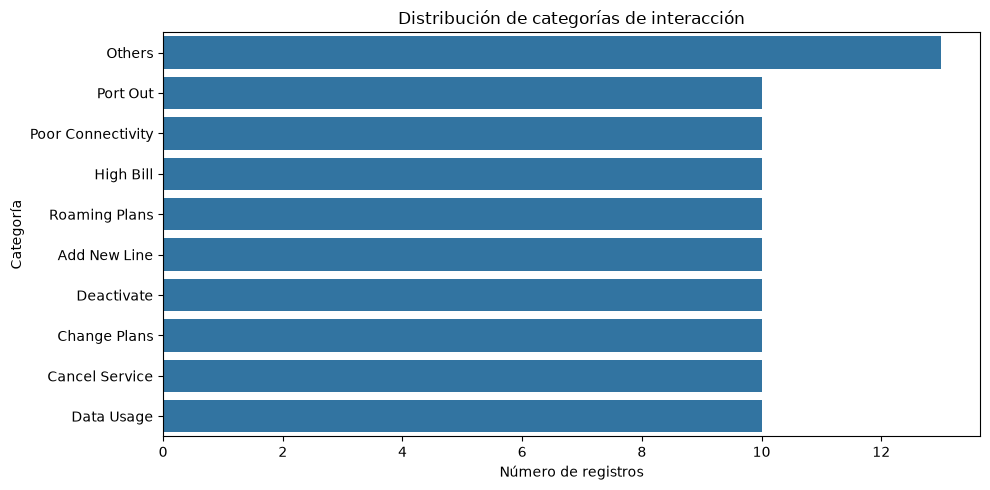

In [8]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    y="AgentAssignedTopic",
    order=df["AgentAssignedTopic"].value_counts().index
)

plt.title("Distribución de categorías de interacción")
plt.xlabel("Número de registros")
plt.ylabel("Categoría")
plt.tight_layout()
plt.show()

In [9]:
# Calcular la cantidad de palabras por interacción
df["longitud_texto"] = df["CustomerInteractionRawText"].apply(
    lambda texto: len(str(texto).split())
)

# Estadísticas descriptivas
display(df["longitud_texto"].describe())

count    103.000000
mean       9.873786
std        3.549868
min        1.000000
25%        7.500000
50%       10.000000
75%       12.000000
max       19.000000
Name: longitud_texto, dtype: float64

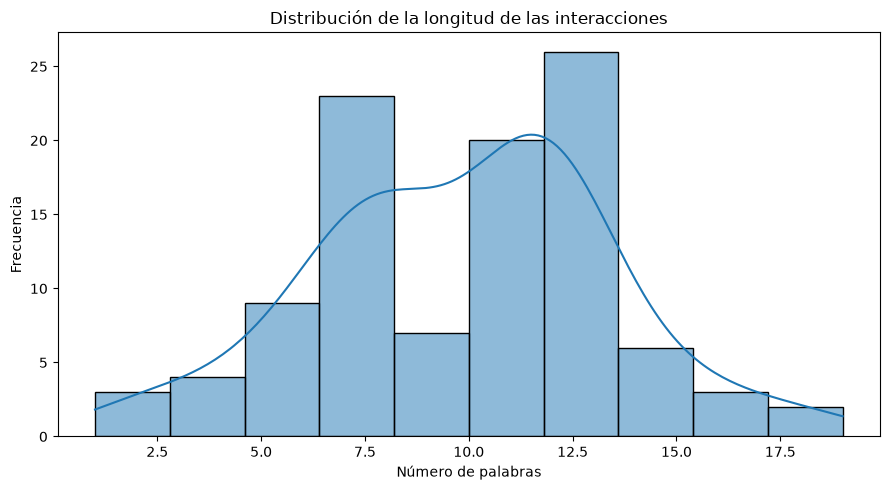

In [10]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="longitud_texto",
    bins=10,
    kde=True
)

plt.title("Distribución de la longitud de las interacciones")
plt.xlabel("Número de palabras")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

La distribución de la longitud de las interacciones muestra que la mayoría de los registros contienen entre 6 y 13 palabras. La longitud promedio es de 9,87 palabras, con una mediana de 10. Se observan algunas interacciones muy cortas y otras de mayor extensión, pero no se identifican valores extremos que requieran un tratamiento especial. Esto indica que el conjunto de datos contiene mensajes relativamente breves.

## 7. Ejemplos de conversaciones por categoría

Se examinan ejemplos de interacciones de cada categoría para identificar patrones en el lenguaje y evaluar cualitativamente la relación entre el texto y la categoría asignada.

In [11]:
# Mostrar dos ejemplos de cada categoría
for categoria in sorted(df["AgentAssignedTopic"].unique()):
    print(f"\nCategoría: {categoria}")
    ejemplos = df.loc[
        df["AgentAssignedTopic"] == categoria,
        "CustomerInteractionRawText"
    ].head(2)

    for ejemplo in ejemplos:
        print("-", ejemplo)


Categoría: Add New Line
- 68347585642 want to add a new connection.
- Customer added a new line. Want to know the status.

Categoría: Cancel Service
- Customer wants to cancel all services & start new ones.
- John Meyer want to cancel the current connection.

Categoría: Change Plans
- Ali want to change plans. He suggested to activate recent offers to his primary number,
- Cus called in to change plan.

Categoría: Data Usage
- Customer called to ask about his Data usage for the past one week.
- Higginbottoms called to check his son's data usage for the last month.

Categoría: Deactivate
- Customer wanted to deactivate existing plans.
- Deactivate current data plans to change to a new local pack.

Categoría: High Bill
- Regina complained about high bill for last month.
- Data plans are very expensive complained 7563453326678

Categoría: Others
- Customer demise.
- IMEI Changed.

Categoría: Poor Connectivity
- Nicki called to inform poor connectivity in Kannur region.
- Low speed connec

## 8. Análisis de términos frecuentes

Se identifican las palabras más frecuentes en las interacciones para conocer el vocabulario predominante del conjunto de datos.

In [13]:
from collections import Counter
import re

# Unir todas las conversaciones
texto_completo = " ".join(df["CustomerInteractionRawText"].astype(str))

# Normalizar el texto y extraer palabras
palabras = re.findall(r"\b[a-zA-Z]+\b", texto_completo.lower())

# Contar las palabras más frecuentes
frecuencia_palabras = Counter(palabras)

# Mostrar las 15 palabras más frecuentes
frecuencia_palabras.most_common(15)

[('to', 86),
 ('customer', 35),
 ('the', 30),
 ('plans', 23),
 ('want', 22),
 ('called', 22),
 ('new', 22),
 ('about', 21),
 ('his', 17),
 ('in', 16),
 ('data', 15),
 ('for', 14),
 ('connection', 13),
 ('usage', 13),
 ('a', 13)]

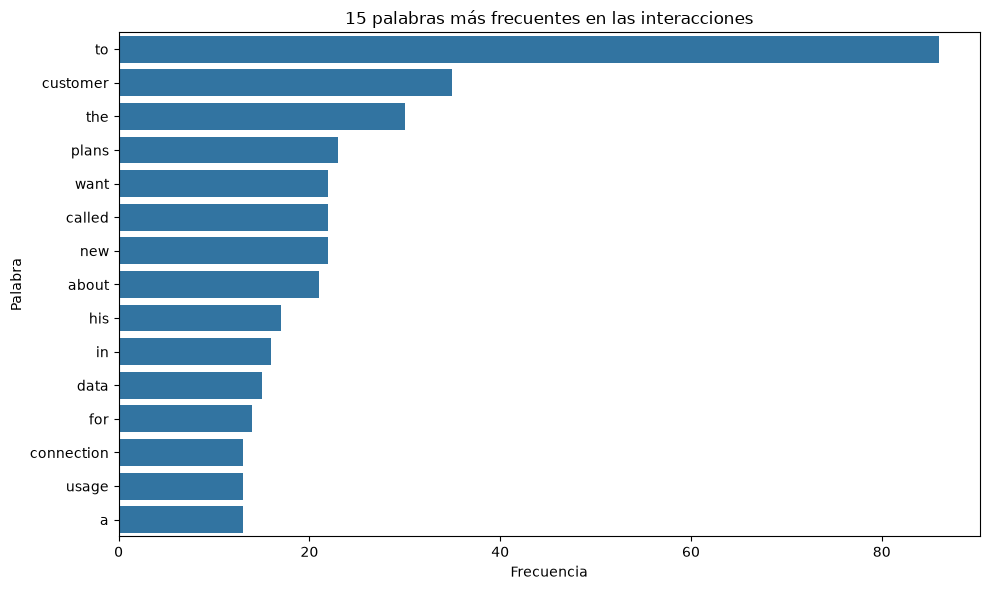

In [14]:
# Obtener las 15 palabras más frecuentes
palabras_frecuentes = frecuencia_palabras.most_common(15)

palabras_df = pd.DataFrame(
    palabras_frecuentes,
    columns=["Palabra", "Frecuencia"]
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=palabras_df,
    x="Frecuencia",
    y="Palabra"
)

plt.title("15 palabras más frecuentes en las interacciones")
plt.xlabel("Frecuencia")
plt.ylabel("Palabra")
plt.tight_layout()
plt.show()

## 9. Conclusiones de la exploración de datos

A partir del análisis exploratorio se identificaron los siguientes aspectos:

1. **Tamaño del conjunto de datos:** se cuenta con 103 registros y 7 columnas.
2. **Calidad de los datos:** las columnas principales para la clasificación (`CustomerInteractionRawText` y `AgentAssignedTopic`) no presentan valores faltantes. Se identificaron algunos valores ausentes en columnas adicionales y no se encontraron registros duplicados.
3. **Distribución de categorías:** el conjunto contiene 10 categorías. La distribución es relativamente equilibrada, con frecuencias entre 10 y 13 registros.
4. **Longitud de las interacciones:** los mensajes tienen un promedio de 9,87 palabras, lo que indica que son textos cortos.
5. **Patrones lingüísticos:** se identificaron expresiones relacionadas con las categorías, aunque existen similitudes semánticas entre algunas de ellas, como `Cancel Service` y `Deactivate`.
6. **Vocabulario:** predominan palabras generales del inglés y términos relacionados con los servicios de telecomunicaciones. Se identifica la necesidad de filtrar palabras comunes durante el preprocesamiento.

### Consideraciones para el modelado

El análisis permite establecer que la clasificación se realizará a partir del texto de las interacciones. Debido al tamaño reducido del conjunto de datos, será importante utilizar validación cruzada y métricas como Macro F1 para evaluar el desempeño del modelo y evitar conclusiones basadas únicamente en la exactitud.